<a href="https://colab.research.google.com/github/tvml/ml2627/blob/master/codici/gp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressione mediante processo gaussiano con scikit-learn

Questo notebook illustra la regressione mediante processi gaussiani con la classe `GaussianProcessRegressor` di scikit-learn, seguendo le note sulla regressione non parametrica. I calcoli sottostanti (matrici di covarianza, condizionamento gaussiano, verosimiglianza marginale) sono implementati passo per passo nel notebook `gaussian_process.ipynb`; qui ci concentriamo sull'uso pratico del modello e sul significato delle sue componenti:

- il **prior** sulle funzioni definito dal kernel, e i campioni che genera;
- il **posterior** dopo l'osservazione dei dati, e come cambia al crescere del numero di osservazioni;
- la scelta degli **iperparametri** mediante massimizzazione della verosimiglianza marginale, e la forma di quest'ultima;
- il trattamento del **rumore**;
- la scelta del **kernel**, che codifica le ipotesi sulla funzione da apprendere (regolarità, periodicità), e il suo effetto in interpolazione ed estrapolazione.

Un processo gaussiano $\mathcal{GP}(m,\kappa)$ è una distribuzione sulle funzioni tale che, per ogni insieme finito di punti, i valori della funzione sono congiuntamente gaussiani, con medie date dalla funzione media $m$ e covarianze date dal kernel $\kappa$. Con media nulla, il kernel determina completamente il prior: un valore grande di $\kappa(x,x')$ significa che $f(x)$ e $f(x')$ tendono a essere simili.

In [ ]:
from IPython.display import Image
import warnings
warnings.filterwarnings('ignore')


In [2]:
import numpy as np
import pandas as pd
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel, Matern, RationalQuadratic, ExpSineSquared

Impostazione dei grafici: usiamo **seaborn**, che costruisce su matplotlib grafici statistici con uno stile più curato; matplotlib resta disponibile per le bande di incertezza (`fill_between`).

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12

colors = ['#008fd5', '#fc4f30', '#e5ae38', '#6d904f', '#8b8b8b', '#810f7c', '#137e6d', '#be0119', '#3b638c', '#af6f09']

Una funzione di supporto per disegnare la distribuzione predittiva di un processo gaussiano: media, banda di $\pm2$ deviazioni standard (circa il $95\%$ della probabilità), alcune funzioni campionate, i dati e, se nota, la funzione vera.

In [4]:
def plot_gp(gp, x, title, X_obs=None, y_obs=None, f_true=None, n_samples=0, ax=None, ylim=(-3, 3), seed=0):
    show = ax is None
    if show:
        fig, ax = plt.subplots(figsize=(16, 7))
    X = x.reshape(-1, 1)
    y_mean, y_std = gp.predict(X, return_std=True)
    ax.fill_between(x, y_mean - 2*y_std, y_mean + 2*y_std, alpha=0.2, color=colors[0], label=r'media $\pm 2\sigma$')
    if n_samples > 0:
        samples = gp.sample_y(X, n_samples, random_state=seed)
        for i in range(n_samples):
            ax.plot(x, samples[:, i], lw=1.2, alpha=.6, color=sns.color_palette('husl', n_samples)[i])
    sns.lineplot(x=x, y=y_mean, color='black', linewidth=2.5, label='media', ax=ax)
    if f_true is not None:
        sns.lineplot(x=x, y=f_true(x), color=colors[1], linewidth=2, linestyle='--', label='funzione vera', ax=ax)
    if X_obs is not None:
        sns.scatterplot(x=X_obs.ravel(), y=y_obs, color=colors[1], s=70, edgecolor='black', zorder=10, label='osservazioni', ax=ax)
    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(*ylim)
    ax.set_title(title)
    ax.legend(loc='lower left')
    if show:
        plt.show()

## Dati

Generiamo il dataset a partire dalla funzione $y=\sin\bigl((x-2.5)^2\bigr)$ su $[0,5]$, campionata in $50$ punti scelti a caso, per ora senza rumore. È una funzione che oscilla sempre più rapidamente allontanandosi dal centro dell'intervallo: la sua "scala di variazione" non è la stessa ovunque, e questo metterà in difficoltà un kernel stazionario come l'RBF, che assume la stessa length scale in tutto il dominio.

In [5]:
def f_true(x):
    return np.sin((x - 2.5) ** 2)

rng = np.random.RandomState(4)
X_tot = rng.uniform(0, 5, 50).reshape(-1, 1)
y_tot = f_true(X_tot[:, 0])
x = np.linspace(0, 5, 400)

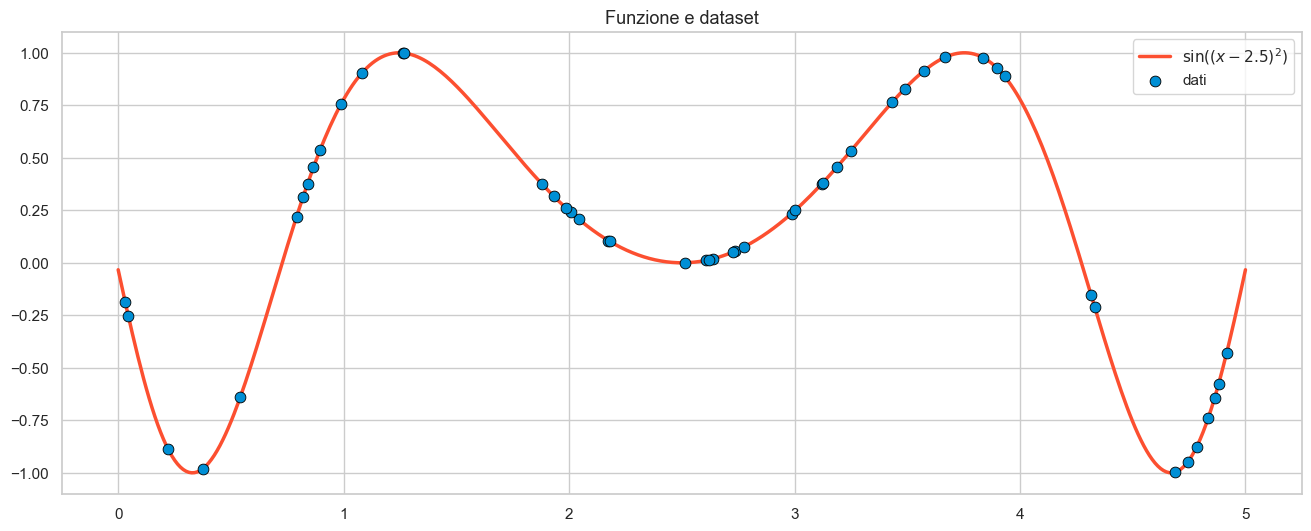

In [6]:
fig, ax = plt.subplots(figsize=(16, 6))
sns.lineplot(x=x, y=f_true(x), color=colors[1], linewidth=2.5, label=r'$\sin((x-2.5)^2)$', ax=ax)
sns.scatterplot(x=X_tot[:, 0], y=y_tot, color=colors[0], s=60, edgecolor='black', zorder=9, label='dati', ax=ax)
ax.set_title('Funzione e dataset')
plt.show()

## Kernel e prior

Definiamo un kernel RBF moltiplicato per una costante:
$$\kappa(x,x')=\sigma_f^2\exp\left(-\frac{(x-x')^2}{2\ell^2}\right),$$
dove $\sigma_f^2$ (`ConstantKernel`) è la **varianza del segnale**, che fissa l'ampiezza tipica delle funzioni, e $\ell$ (`length_scale` di `RBF`) è la **length scale**, la distanza oltre la quale i valori della funzione diventano praticamente indipendenti. Per ciascun iperparametro si indica il valore iniziale e un intervallo in cui l'ottimizzatore lo cercherà.

Il regressore `GaussianProcessRegressor` ha un argomento `alpha`, un valore aggiunto alla diagonale della matrice di covarianza dei dati di training, $\mathbf{G}_{\mathbf{X}}+\alpha\mathbf{I}$. Ha due ruoli: numerico, perché rende la matrice ben condizionata e invertibile, e modellistico, perché corrisponde alla **varianza del rumore** $\sigma_n^2$ assunta nel modello delle osservazioni, $t_i=f(x_i)+\varepsilon_i$ con $\varepsilon_i\sim\mathcal{N}(0,\sigma_n^2)$. Si noti che è una varianza: `alpha=0.1` corrisponde a $\sigma_n\approx0.32$. Qui i dati non hanno rumore, e il valore scelto rende il modello più "tollerante" di quanto sarebbe necessario: torneremo sulla questione più avanti.

In [7]:
sigma_f2 = 1.      # varianza del segnale
l = .5             # length scale
kernel = ConstantKernel(sigma_f2, constant_value_bounds=(1e-2, 1e2)) * RBF(length_scale=l, length_scale_bounds=(1e-1, 10.0))

sigma_n2 = .1      # varianza del rumore assunta nel modello
gp = GaussianProcessRegressor(kernel=kernel, alpha=sigma_n2, random_state=0)

Prima dell'apprendimento, il regressore rappresenta il **prior**: `predict` restituisce media nulla e deviazione standard $\sigma_f=1$ in ogni punto, e `sample_y` genera funzioni campionate dal processo. Sono funzioni che oscillano su una scala dell'ordine di $\ell=0.5$ e hanno valori tipicamente in $[-2\sigma_f,2\sigma_f]$.

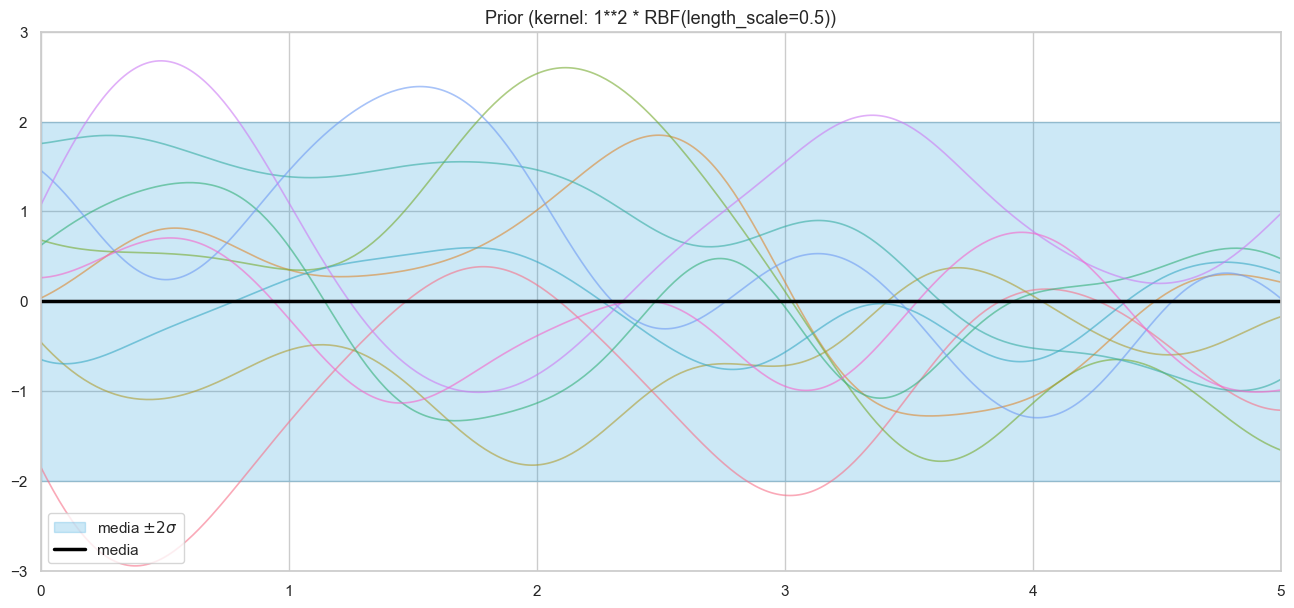

In [9]:
plot_gp(gp, x, "Prior (kernel: %s)" % kernel, n_samples=10)

## Posterior

Con `fit` il regressore apprende dai dati. Due operazioni avvengono contemporaneamente:

1. gli iperparametri del kernel ($\sigma_f^2$ e $\ell$, entro gli intervalli indicati) sono scelti massimizzando la **verosimiglianza marginale** dei dati, discussa più avanti (`alpha`, non essendo un iperparametro del kernel, resta fisso);
2. il processo viene **condizionato** sulle osservazioni: come nelle note, la distribuzione a posteriori dei valori nei punti di test $\mathbf{Z}$ è gaussiana, con
$$\boldsymbol\mu_p=\mathbf{G}_{\mathbf{Z},\mathbf{X}}\hat{\boldsymbol\Sigma}_{\mathbf{X}}^{-1}\mathbf{t},\qquad \boldsymbol\Sigma_p=\mathbf{G}_{\mathbf{Z}}-\mathbf{G}_{\mathbf{Z},\mathbf{X}}\hat{\boldsymbol\Sigma}_{\mathbf{X}}^{-1}\mathbf{G}_{\mathbf{Z},\mathbf{X}}^T,\qquad \hat{\boldsymbol\Sigma}_{\mathbf{X}}=\mathbf{G}_{\mathbf{X}}+\sigma_n^2\mathbf{I}.$$

Il kernel con gli iperparametri iniziali resta in `gp.kernel`, quello con gli iperparametri appresi è in `gp.kernel_`. Apprendiamo dapprima dai soli primi $10$ punti.

In [10]:
n = 10
X_tr = X_tot[:n]
y_tr = y_tot[:n]
gp = gp.fit(X_tr, y_tr)
print('kernel iniziale: {0}'.format(gp.kernel))
print('kernel appreso:  {0}'.format(gp.kernel_))
print('log verosimiglianza marginale: {0:.3f}'.format(gp.log_marginal_likelihood_value_))

kernel iniziale: 1**2 * RBF(length_scale=0.5)
kernel appreso:  0.584**2 * RBF(length_scale=0.511)
log verosimiglianza marginale: -6.125


Funzioni campionate dal posterior, con media e banda. Le funzioni passano vicino alle osservazioni ma non esattamente per esse, perché il modello assume un rumore di varianza $0.1$: la banda non si annulla nei punti di training. Tra le osservazioni e soprattutto ai margini dell'intervallo, dove mancano i dati, l'incertezza cresce e la media torna verso lo zero, la media del prior.

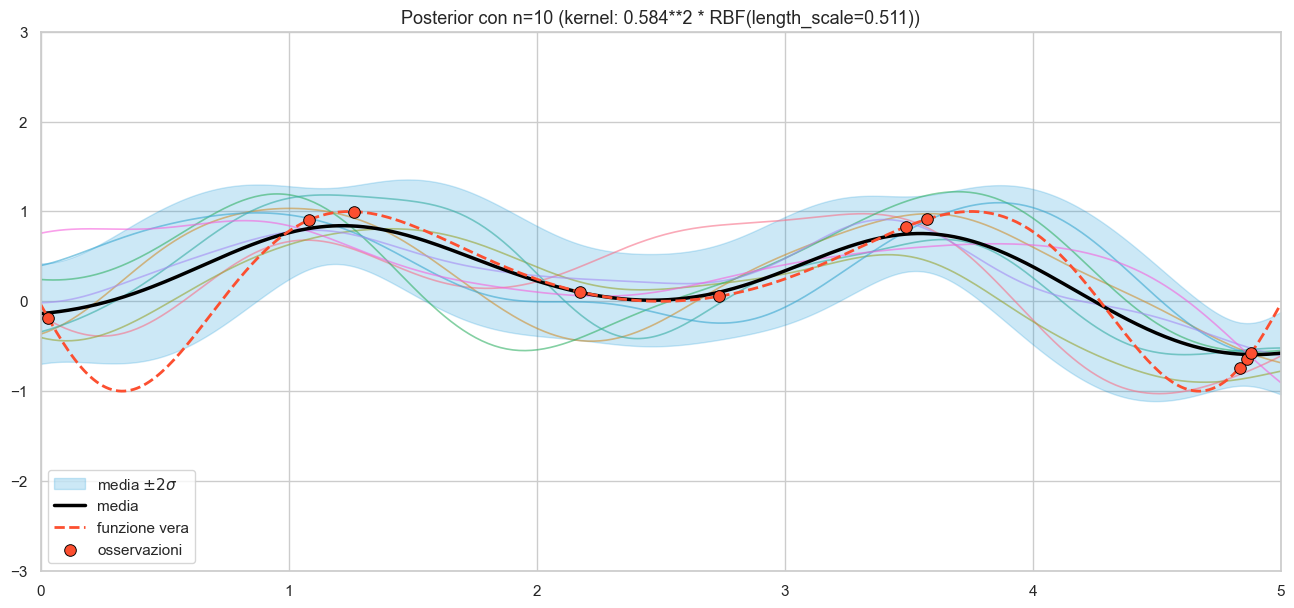

In [11]:
plot_gp(gp, x, "Posterior con n={0} (kernel: {1})".format(n, gp.kernel_), X_tr, y_tr, f_true=f_true, n_samples=8)

### Al crescere del numero di osservazioni

Come cambia il posterior quando aggiungiamo osservazioni? Ripetiamo l'apprendimento con $n=2,5,10,20,35,50$ punti. Con pochi punti il posterior è molto vicino al prior, salvo in prossimità delle osservazioni; al crescere di $n$ la banda si restringe nelle regioni coperte dai dati e la media si avvicina alla funzione vera. Notiamo anche che gli iperparametri appresi cambiano con $n$: con pochi dati la verosimiglianza marginale non è in grado di determinarli con precisione.

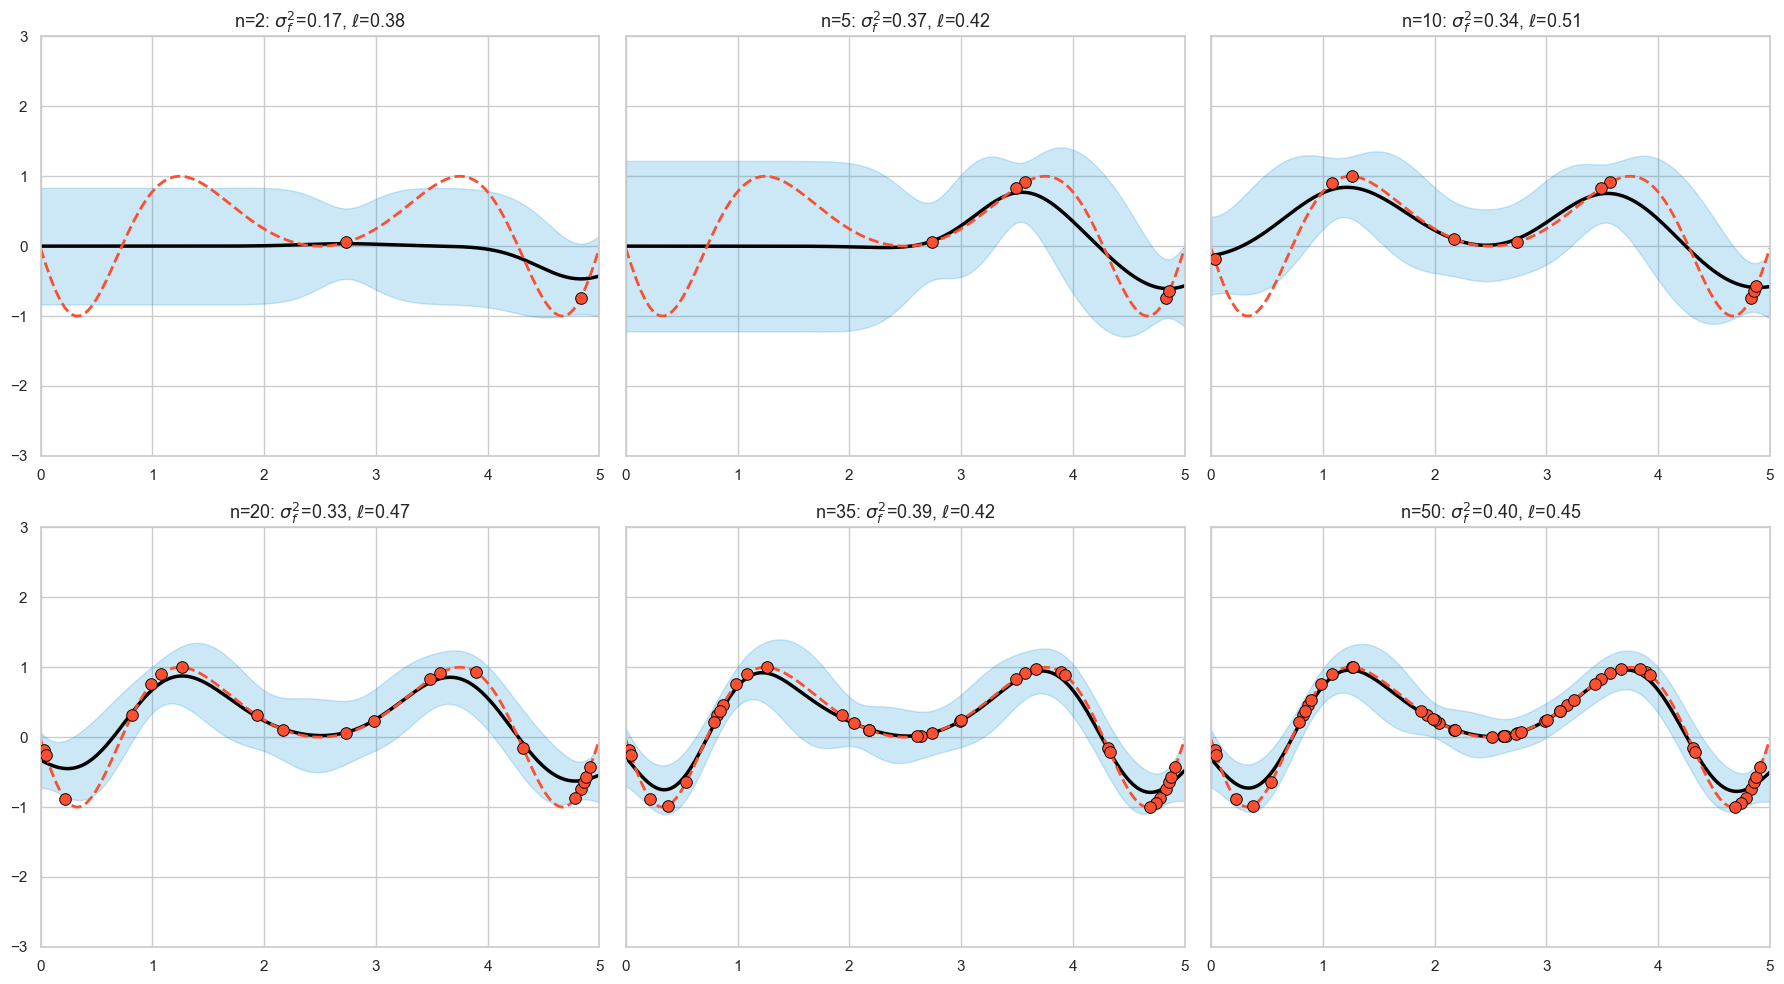

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharey=True)
for ax, n_ in zip(axes.ravel(), [2, 5, 10, 20, 35, 50]):
    g = GaussianProcessRegressor(kernel=kernel, alpha=sigma_n2, random_state=0).fit(X_tot[:n_], y_tot[:n_])
    plot_gp(g, x, r'n={0}: $\sigma_f^2$={1:.2f}, $\ell$={2:.2f}'.format(n_, g.kernel_.k1.constant_value, g.kernel_.k2.length_scale),
            X_tot[:n_], y_tot[:n_], f_true=f_true, ax=ax)
    ax.get_legend().remove()
plt.tight_layout()
plt.show()

Apprendimento su tutti i valori del training set, e confronto delle predizioni con la funzione originaria:

kernel appreso: 0.632**2 * RBF(length_scale=0.446)


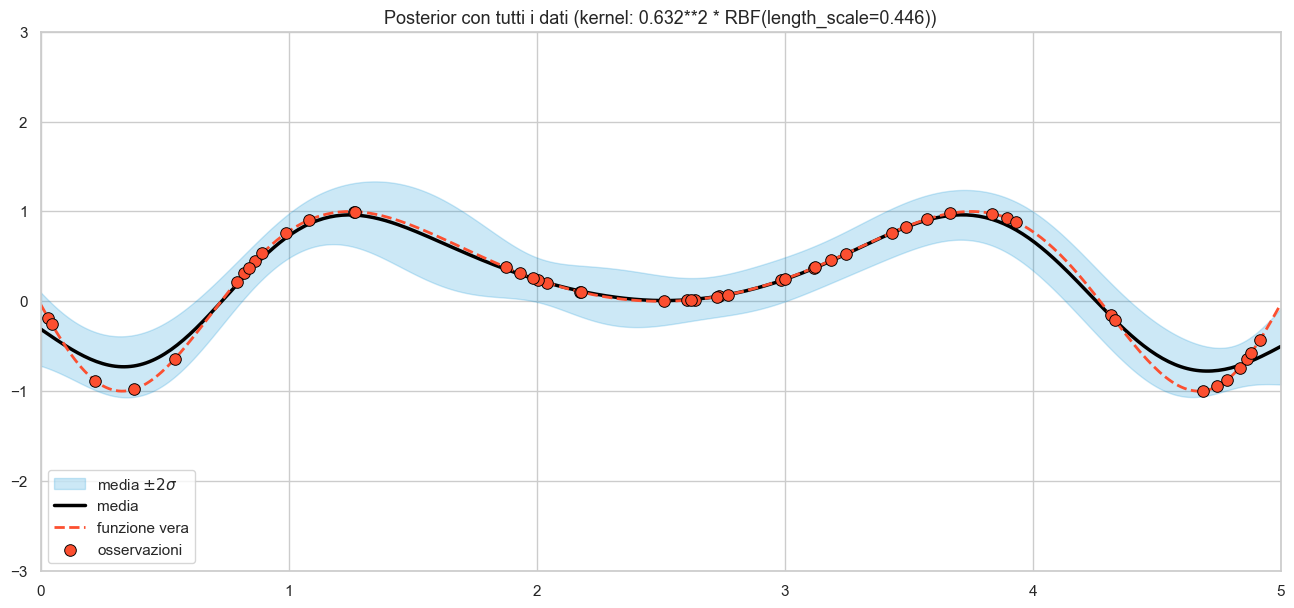

In [13]:
gp = gp.fit(X_tot, y_tot)
print('kernel appreso: {0}'.format(gp.kernel_))
plot_gp(gp, x, "Posterior con tutti i dati (kernel: %s)" % gp.kernel_, X_tot, y_tot, f_true=f_true)

La media segue bene la funzione al centro dell'intervallo, ma ai margini, dove la funzione oscilla più rapidamente, la approssima peggio: la length scale appresa è un compromesso tra le regioni a variazione lenta e quelle a variazione rapida. È il limite di un kernel **stazionario**, che dipende solo da $x-x'$ e assume quindi la stessa regolarità ovunque. Inoltre, l'ipotesi di un rumore di varianza $0.1$, che qui non c'è, porta il modello a non passare per i dati: le osservazioni ai margini vengono in parte spiegate come rumore.

## La verosimiglianza marginale

Come visto nelle note, gli iperparametri $\boldsymbol\theta$ sono scelti massimizzando la verosimiglianza marginale dei target,
$$\log p(\mathbf{t}\mid\mathbf{X};\boldsymbol\theta)=-\frac12\mathbf{t}^T\hat{\boldsymbol\Sigma}_{\mathbf{X}}^{-1}\mathbf{t}-\frac12\log|\hat{\boldsymbol\Sigma}_{\mathbf{X}}|-\frac n2\log(2\pi),$$
che bilancia l'**adattamento** ai dati (primo termine) e una **penalità di complessità** (secondo termine), più grande per i modelli flessibili, come quelli con length scale piccola. Il metodo `log_marginal_likelihood` del regressore calcola questo valore per un vettore di iperparametri, espressi come **logaritmi** (`gp.kernel_.theta`), la parametrizzazione usata internamente dall'ottimizzatore.

Calcoliamo la log verosimiglianza marginale su una griglia di valori di $\sigma_f^2$ e $\ell$, per il modello appreso su tutti i dati, e la rappresentiamo con una heatmap.

iperparametri appresi (log): [-0.91825507 -0.80652672]


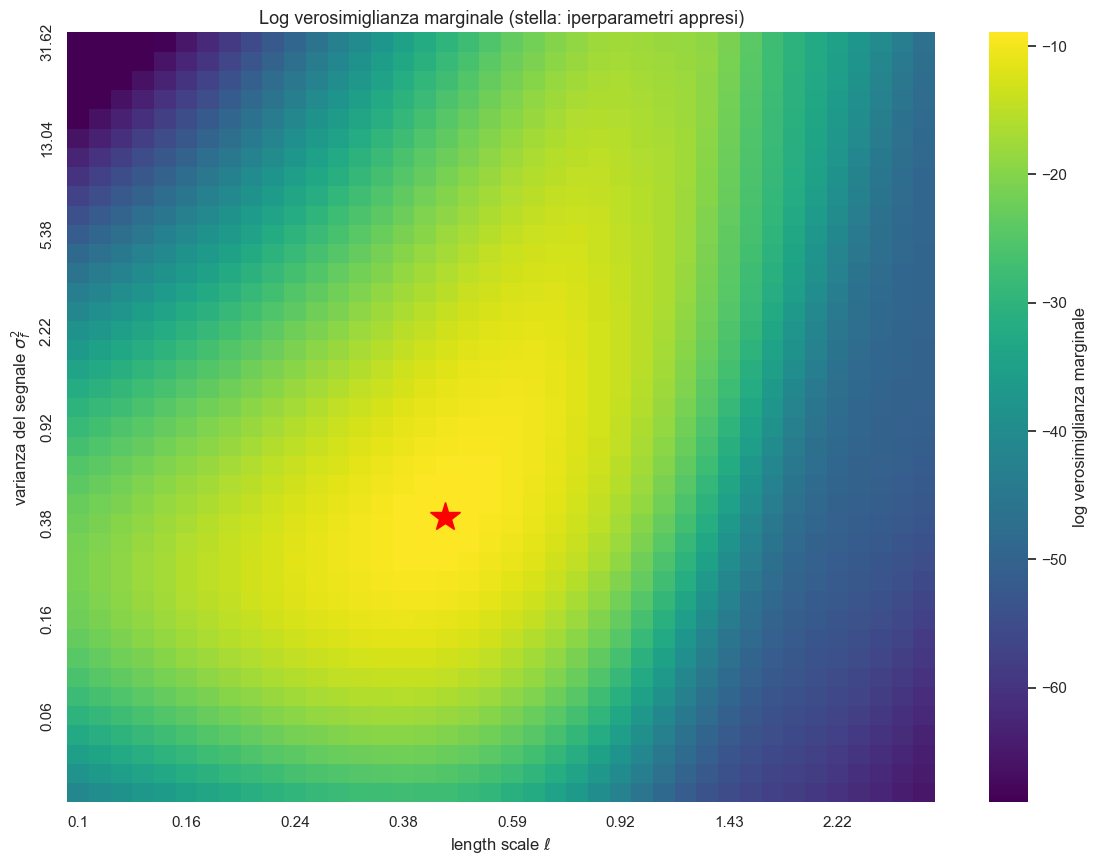

In [14]:
print('iperparametri appresi (log): {0}'.format(gp.kernel_.theta))
grid_c = np.logspace(-1.5, 1.5, 40)
grid_l = np.logspace(-1, 0.5, 40)
LML = np.array([[gp.log_marginal_likelihood(np.log([c, ll])) for ll in grid_l] for c in grid_c])
lml_df = pd.DataFrame(np.maximum(LML, LML.max() - 60), index=np.round(grid_c, 2), columns=np.round(grid_l, 2))

plt.figure(figsize=(14, 10))
ax = sns.heatmap(lml_df[::-1], cmap='viridis', xticklabels=5, yticklabels=5, cbar_kws={'label': 'log verosimiglianza marginale'})
c_opt, l_opt = np.exp(gp.kernel_.theta)
ax.plot(np.interp(np.log(l_opt), np.log(grid_l), np.arange(len(grid_l))) + .5,
        len(grid_c) - np.interp(np.log(c_opt), np.log(grid_c), np.arange(len(grid_c))) - .5, marker='*', color='red', ms=22)
ax.set_xlabel(r'length scale $\ell$')
ax.set_ylabel(r'varianza del segnale $\sigma_f^2$')
ax.set_title('Log verosimiglianza marginale (stella: iperparametri appresi)')
plt.show()

La regione di massimo è allungata in diagonale: length scale e ampiezza sono in parte intercambiabili nello spiegare i dati, perché una funzione più ampia con length scale maggiore può avere pendenze simili a una meno ampia con length scale minore. Al di fuori di questa regione la verosimiglianza crolla rapidamente, soprattutto verso length scale grandi, per le quali le funzioni del prior sono troppo lisce per seguire le oscillazioni dei dati.

Separiamo ora i due termini della verosimiglianza marginale al variare di $\ell$, con $\sigma_f^2$ fissato al valore appreso. Li calcoliamo direttamente a partire dalla matrice di covarianza dei dati di training, con la fattorizzazione di Cholesky.

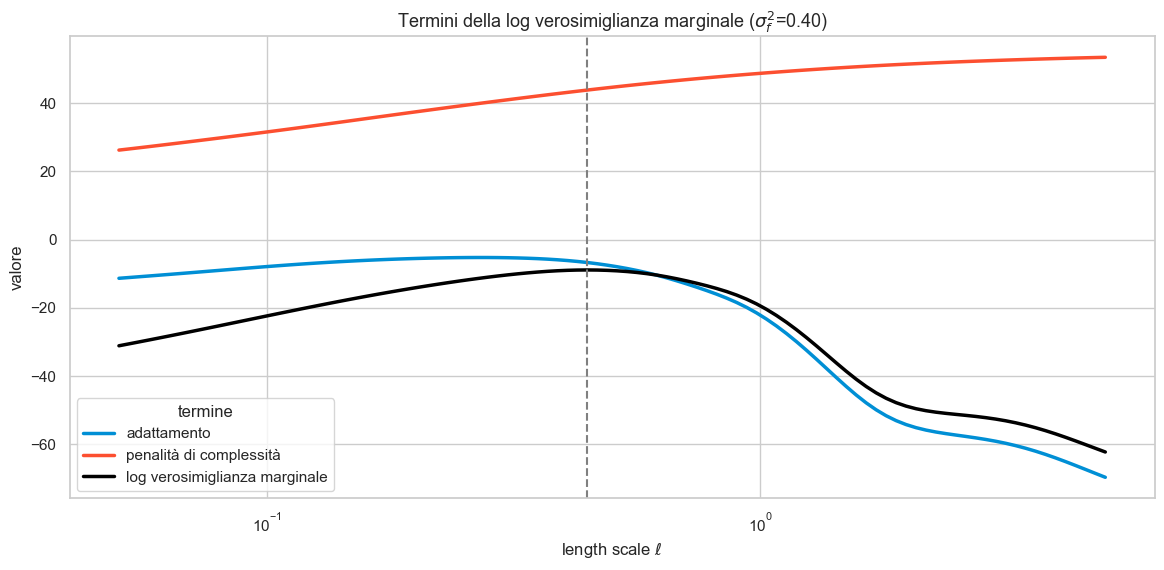

In [15]:
def lml_terms(c, ll, X, t, noise_var):
    K = c * np.exp(-(X - X.T)**2 / (2*ll**2)) + noise_var * np.eye(len(t))
    L = np.linalg.cholesky(K)
    a = np.linalg.solve(L.T, np.linalg.solve(L, t))
    return -0.5 * t @ a, -np.sum(np.log(np.diag(L)))

ls = np.logspace(-1.3, 0.7, 100)
T = np.array([lml_terms(c_opt, ll, X_tot, y_tot, sigma_n2) for ll in ls])
td = pd.DataFrame({'l': np.tile(ls, 3), 'valore': np.concatenate([T[:,0], T[:,1], T.sum(1) - len(y_tot)/2*np.log(2*np.pi)]),
                   'termine': np.repeat(['adattamento', 'penalità di complessità', 'log verosimiglianza marginale'], len(ls))})
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=td, x='l', y='valore', hue='termine', palette=[colors[0], colors[1], 'black'], linewidth=2.5, ax=ax)
ax.axvline(l_opt, color='grey', ls='--')
ax.set_xscale('log')
ax.set_xlabel(r'length scale $\ell$')
ax.set_title(r'Termini della log verosimiglianza marginale ($\sigma_f^2$={0:.2f})'.format(c_opt))
plt.show()

Il termine di adattamento diminuisce al crescere di $\ell$, perché funzioni più lisce spiegano peggio i dati; la penalità di complessità, al contrario, cresce (diventa meno negativa), perché un modello più rigido distribuisce la probabilità su un insieme più piccolo di possibili target. Il massimo della somma corrisponde alla length scale appresa (linea tratteggiata).

Cosa succede se non si ottimizzano gli iperparametri? Con `optimizer=None` il regressore usa i valori iniziali. Confrontiamo tre length scale fissate: troppo piccola, appresa e troppo grande.

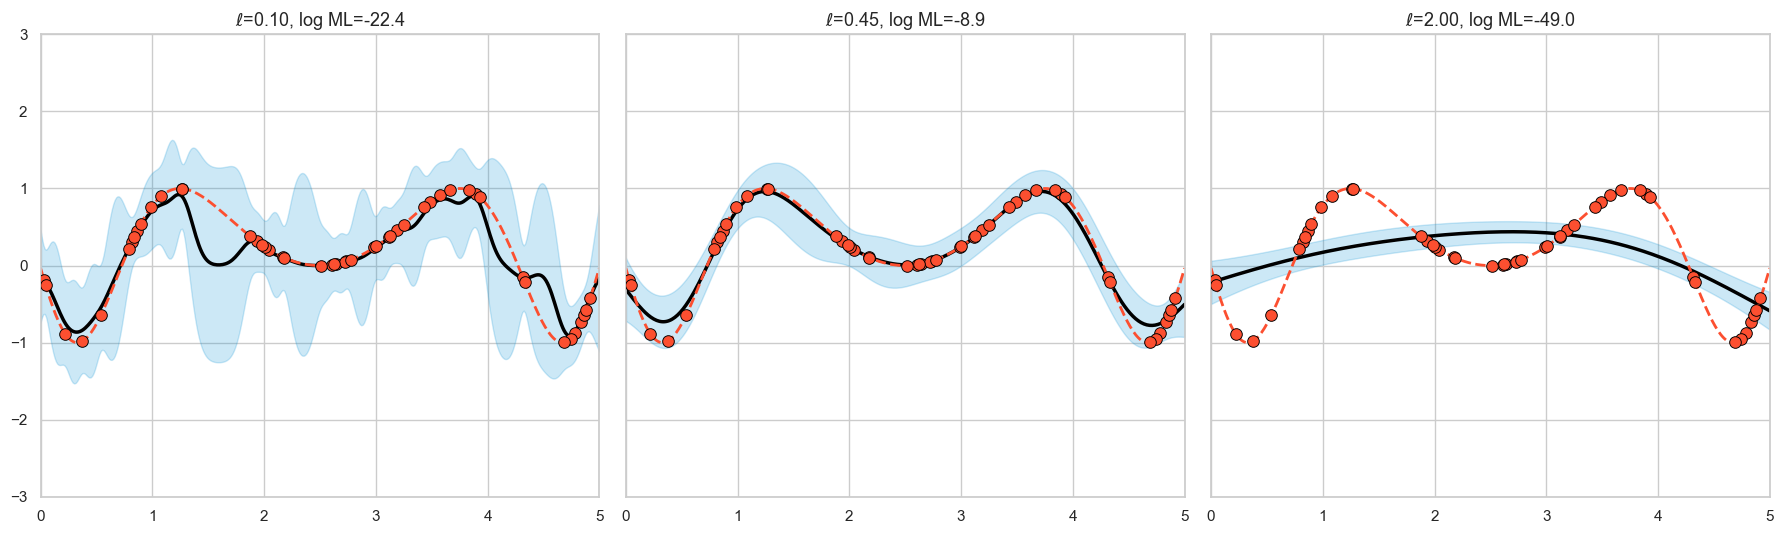

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for ax, ll in zip(axes, [0.1, l_opt, 2.]):
    g = GaussianProcessRegressor(kernel=ConstantKernel(c_opt) * RBF(ll), alpha=sigma_n2, optimizer=None).fit(X_tot, y_tot)
    plot_gp(g, x, r'$\ell$={0:.2f}, log ML={1:.1f}'.format(ll, g.log_marginal_likelihood_value_), X_tot, y_tot, f_true=f_true, ax=ax)
    ax.get_legend().remove()
plt.tight_layout()
plt.show()

Con $\ell=0.1$ il modello è molto flessibile ma, con il rumore assunto, torna verso zero tra punti distanti e ha una banda larga ovunque; con $\ell=2$ è troppo rigido e ignora completamente le oscillazioni ai margini, che attribuisce al rumore. La verosimiglianza marginale, riportata nei titoli, è massima per il valore appreso.

## Il rumore

Finora il rumore è stato fissato con `alpha`. Più realisticamente, generiamo osservazioni rumorose, con deviazione standard $\sigma_n=0.2$, e lasciamo che il modello **apprenda** il livello del rumore, aggiungendo al kernel un `WhiteKernel`:
$$\kappa(x,x')=\sigma_f^2\exp\left(-\frac{(x-x')^2}{2\ell^2}\right)+\sigma_n^2\,\delta(x,x'),$$
dove $\delta(x,x')=1$ se $x=x'$ e $0$ altrimenti. Il termine aggiunge $\sigma_n^2$ sulla diagonale della matrice di covarianza dei dati, esattamente come `alpha`, ma con un valore che è ora un iperparametro, scelto anch'esso massimizzando la verosimiglianza marginale.

In [17]:
sigma_n = 0.2
rng_n = np.random.RandomState(1)
X_noisy = np.sort(rng_n.uniform(0, 5, 40)).reshape(-1, 1)
y_noisy = f_true(X_noisy[:, 0]) + rng_n.normal(0, sigma_n, 40)

kernel_noise = ConstantKernel(1., (1e-2, 1e2)) * RBF(.5, (1e-1, 10.)) + WhiteKernel(noise_level=.1, noise_level_bounds=(1e-5, 1.))
gp_noise = GaussianProcessRegressor(kernel=kernel_noise, alpha=1e-10, n_restarts_optimizer=5, random_state=0).fit(X_noisy, y_noisy)
print('kernel appreso: {0}'.format(gp_noise.kernel_))
print('sigma_n stimato: {0:.3f} (vero: {1})'.format(np.sqrt(gp_noise.kernel_.k2.noise_level), sigma_n))

kernel appreso: 0.723**2 * RBF(length_scale=0.39) + WhiteKernel(noise_level=0.0239)
sigma_n stimato: 0.154 (vero: 0.2)


Confrontiamo il modello che apprende il rumore con due modelli in cui il rumore è fissato con `alpha`: troppo piccolo ($\sigma_n^2=10^{-6}$) e troppo grande ($\sigma_n^2=1$).

- Con il rumore appreso, il modello **liscia** i dati e la media resta vicina alla funzione vera.
- Con un rumore assunto troppo piccolo, il modello è costretto a **interpolare** le osservazioni rumorose: per riuscirci la verosimiglianza marginale sceglie la length scale più piccola consentita, e la media oscilla violentemente per passare per osservazioni vicine con valori diversi, un caso estremo di overfitting.
- Con un rumore assunto troppo grande, quasi tutte le variazioni dei dati sono attribuite al rumore, e la media è eccessivamente liscia: underfitting.

Si noti che con il `WhiteKernel` la deviazione standard restituita da `predict` include il rumore, ed è quindi quella di una nuova osservazione; con `alpha`, invece, il rumore non è incluso.

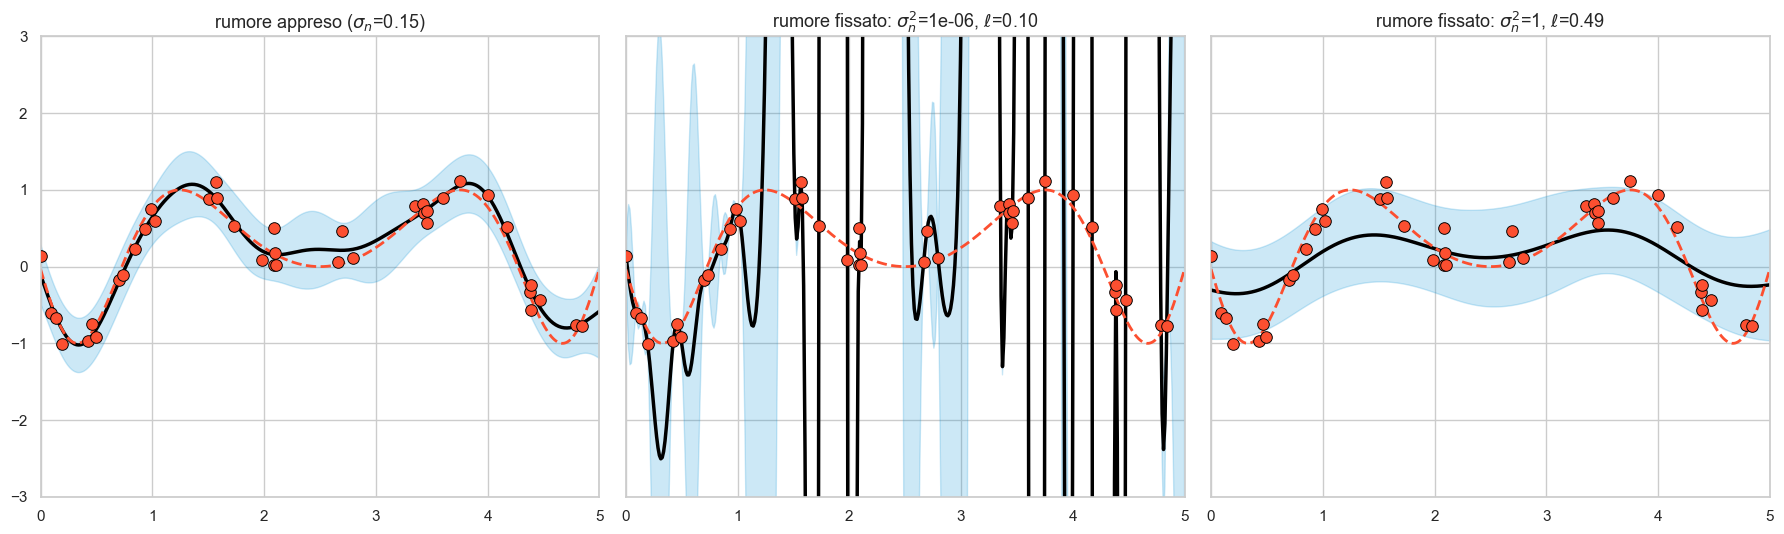

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
plot_gp(gp_noise, x, r'rumore appreso ($\sigma_n$={0:.2f})'.format(np.sqrt(gp_noise.kernel_.k2.noise_level)), X_noisy, y_noisy, f_true=f_true, ax=axes[0])
for ax, a in zip(axes[1:], [1e-6, 1.]):
    g = GaussianProcessRegressor(kernel=ConstantKernel(1., (1e-2, 1e2)) * RBF(.5, (1e-1, 10.)), alpha=a, n_restarts_optimizer=5, random_state=0).fit(X_noisy, y_noisy)
    plot_gp(g, x, r'rumore fissato: $\sigma_n^2$={0:g}, $\ell$={1:.2f}'.format(a, g.kernel_.k2.length_scale), X_noisy, y_noisy, f_true=f_true, ax=ax)
for ax in axes:
    ax.get_legend().remove()
plt.tight_layout()
plt.show()

## La scelta del kernel

Il kernel codifica le ipotesi sulla funzione da apprendere. scikit-learn mette a disposizione diversi kernel, che si possono anche combinare con somme e prodotti, poiché somme e prodotti di kernel definiti positivi sono definiti positivi, come osservato nelle note:

- **RBF**: funzioni infinitamente derivabili, molto lisce;
- **Matérn** con parametro $\nu$: funzioni derivabili $\lceil\nu\rceil-1$ volte; per $\nu=1/2$ (kernel esponenziale, $e^{-|x-x'|/\ell}$) le funzioni sono continue ma non derivabili, per $\nu\to\infty$ si ritrova l'RBF. È spesso più realistico dell'RBF, la cui regolarità è eccessiva per molti fenomeni reali;
- **Rational quadratic**: una miscela di RBF con length scale diverse, adatta a funzioni che variano su più scale;
- **ExpSineSquared**: un kernel **periodico**, $\exp\left(-\frac{2\sin^2(\pi|x-x'|/p)}{\ell^2}\right)$, con periodo $p$, per funzioni che si ripetono.

Le funzioni campionate dai rispettivi prior mostrano le diverse ipotesi:

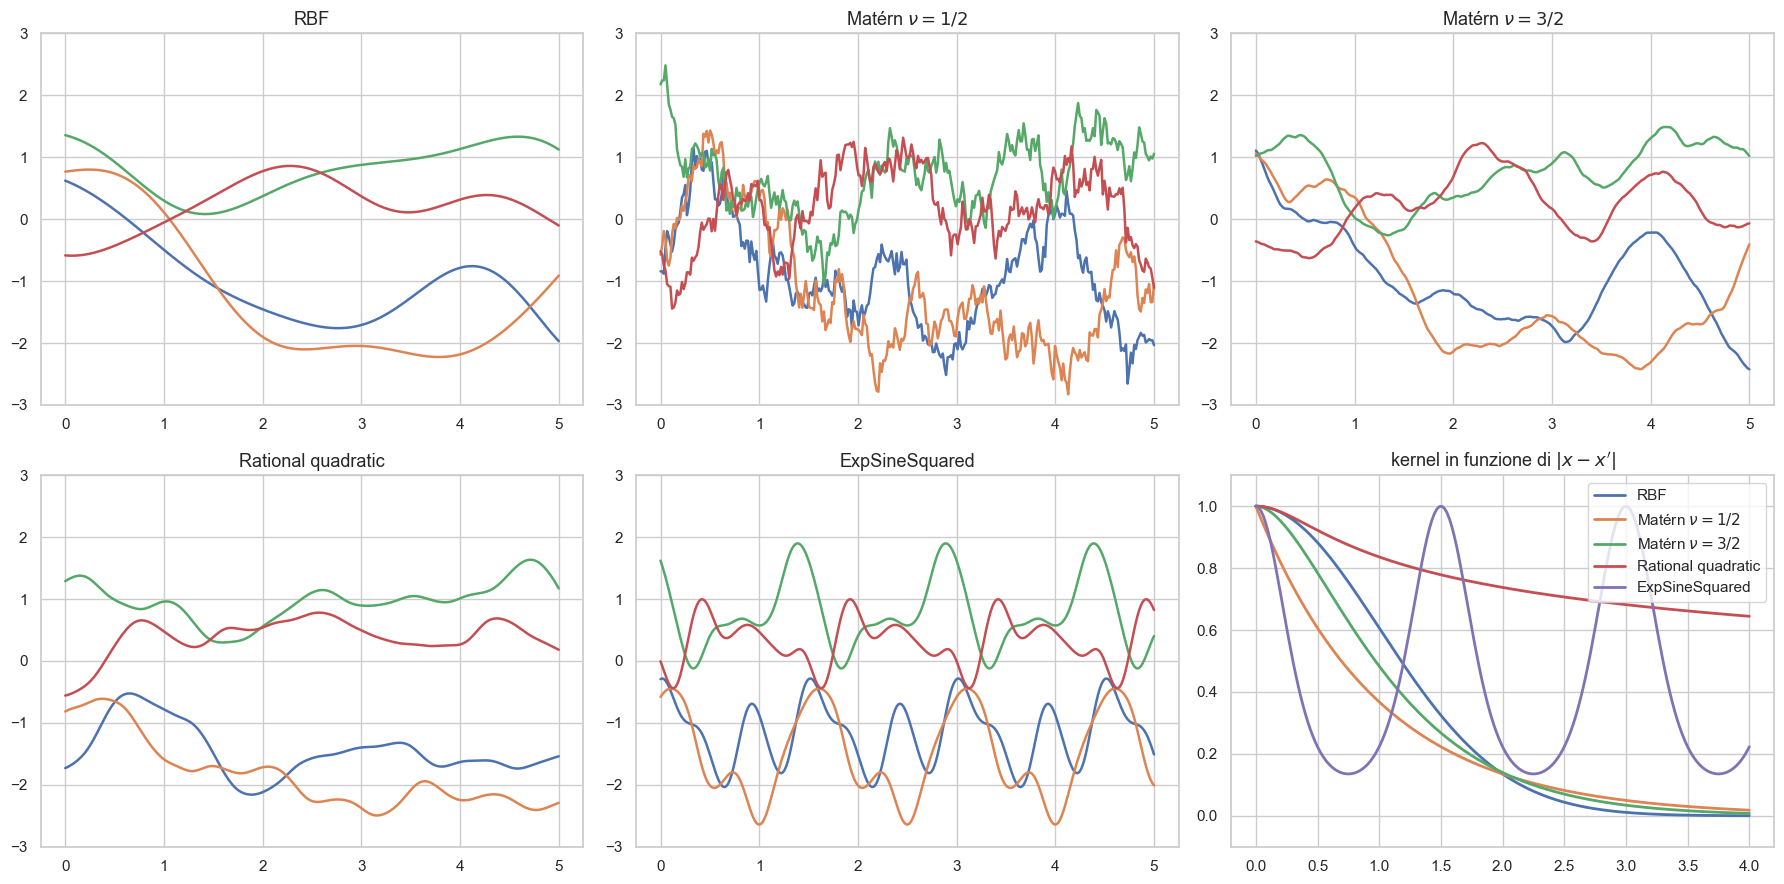

In [19]:
kernels = {
    'RBF': ConstantKernel(1.) * RBF(1.),
    r'Matérn $\nu=1/2$': ConstantKernel(1.) * Matern(1., nu=0.5),
    r'Matérn $\nu=3/2$': ConstantKernel(1.) * Matern(1., nu=1.5),
    'Rational quadratic': ConstantKernel(1.) * RationalQuadratic(length_scale=1., alpha=0.1),
    'ExpSineSquared': ConstantKernel(1.) * ExpSineSquared(length_scale=1., periodicity=1.5),
}
xk = np.linspace(0, 5, 300)
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (name, k) in zip(axes.ravel(), kernels.items()):
    g = GaussianProcessRegressor(kernel=k)
    s = g.sample_y(xk.reshape(-1, 1), 4, random_state=1)
    for i in range(4):
        sns.lineplot(x=xk, y=s[:, i], linewidth=1.8, ax=ax)
    ax.set_title(name)
    ax.set_ylim(-3, 3)
# il kernel come funzione della distanza
axk = axes.ravel()[-1]
u = np.linspace(0, 4, 200).reshape(-1, 1)
for name, k in kernels.items():
    sns.lineplot(x=u.ravel(), y=k(np.zeros((1, 1)), u)[0], linewidth=2, label=name, ax=axk)
axk.set_title("kernel in funzione di $|x-x'|$")
axk.set_ylim(-.1, 1.1)
plt.tight_layout()
plt.show()

Confrontiamo i kernel sui dati rumorosi della sezione precedente, aggiungendo a ciascuno un `WhiteKernel` per il rumore. Per ogni kernel riportiamo la log verosimiglianza marginale e l'errore quadratico medio rispetto alla funzione vera. La verosimiglianza marginale permette di confrontare modelli diversi senza dati di validazione: è la stessa quantità usata per scegliere gli iperparametri, applicata ora alla scelta del kernel.

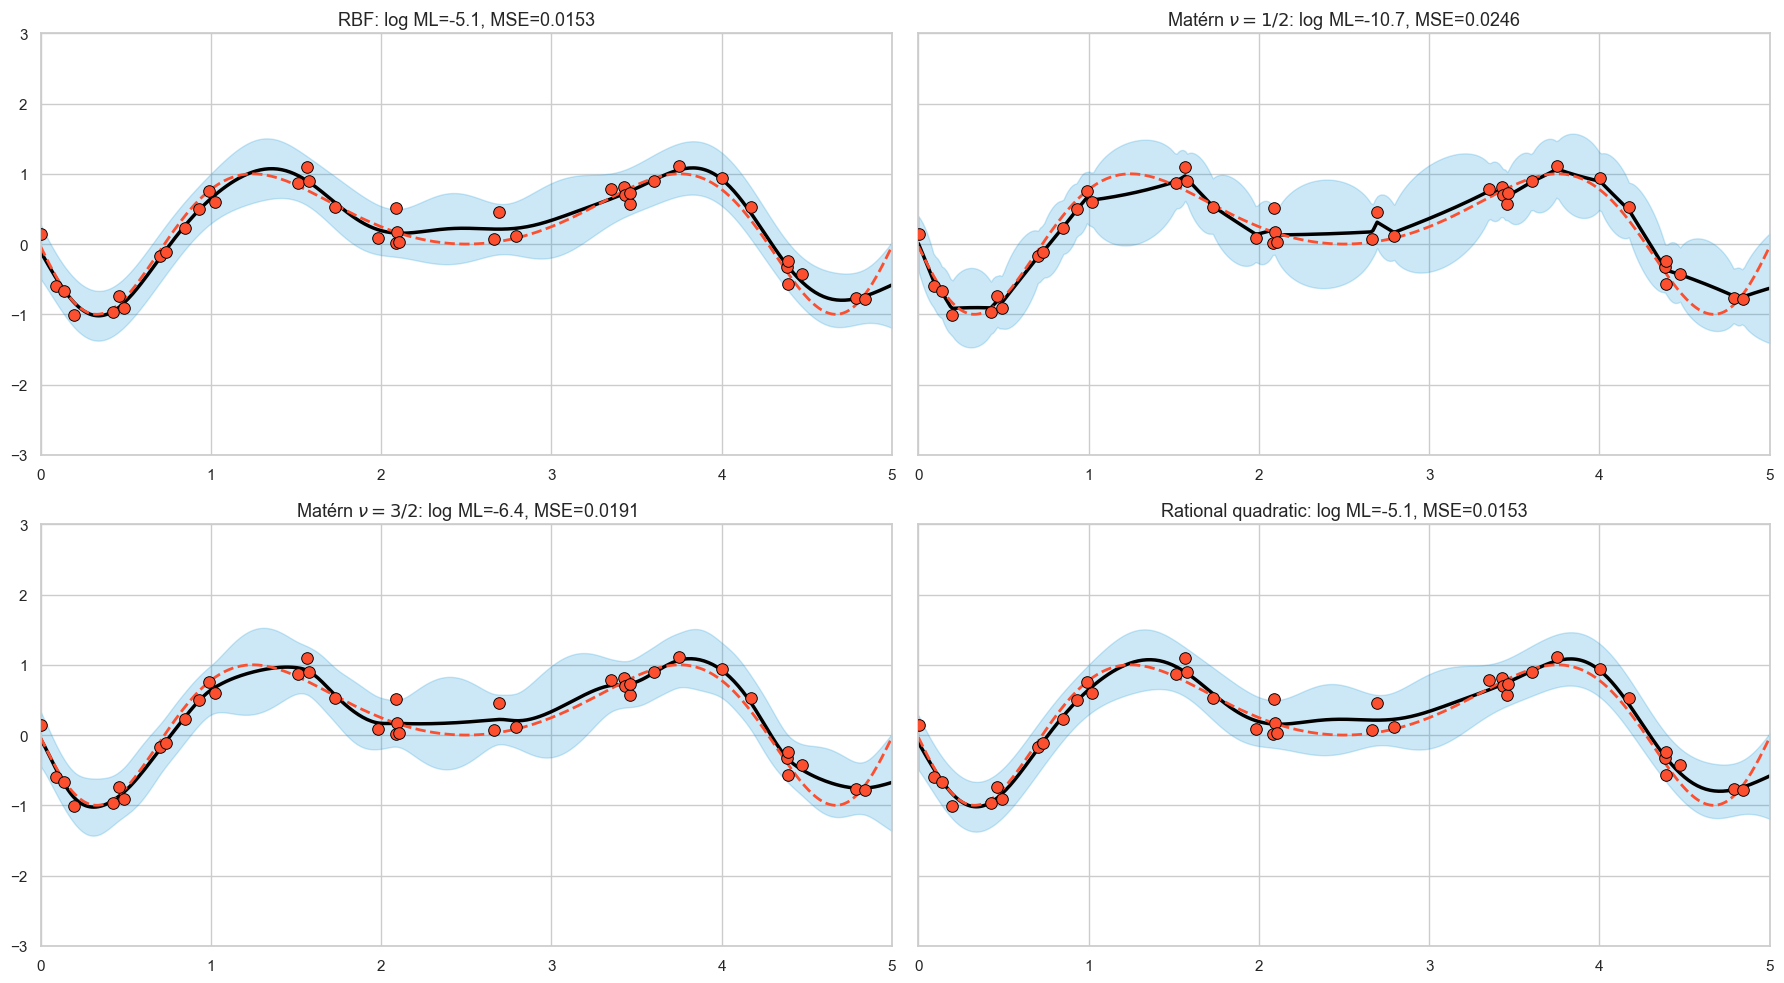

,kernel,log verosimiglianza marginale,MSE rispetto a f
0,RBF,-5.0782,0.0153
1,Matérn $\nu=1/2$,-10.6803,0.0246
2,Matérn $\nu=3/2$,-6.4301,0.0191
3,Rational quadratic,-5.0782,0.0153


In [20]:
res = []
fig, axes = plt.subplots(2, 2, figsize=(18, 10), sharey=True)
for ax, name in zip(axes.ravel(), ['RBF', r'Matérn $\nu=1/2$', r'Matérn $\nu=3/2$', 'Rational quadratic']):
    k = kernels[name] + WhiteKernel(.1, (1e-5, 1.))
    g = GaussianProcessRegressor(kernel=k, n_restarts_optimizer=5, random_state=0).fit(X_noisy, y_noisy)
    mse = np.mean((g.predict(x.reshape(-1, 1)) - f_true(x))**2)
    res.append([name, g.log_marginal_likelihood_value_, mse])
    plot_gp(g, x, '{0}: log ML={1:.1f}, MSE={2:.4f}'.format(name, g.log_marginal_likelihood_value_, mse), X_noisy, y_noisy, f_true=f_true, ax=ax)
    ax.get_legend().remove()
plt.tight_layout()
plt.show()
pd.DataFrame(res, columns=['kernel', 'log verosimiglianza marginale', 'MSE rispetto a f']).round(4)

Il kernel di Matérn con $\nu=1/2$ produce una media irregolare, con piccoli spigoli in corrispondenza delle osservazioni, perché le funzioni del suo prior non sono derivabili; gli altri kernel producono medie lisce e simili tra loro. La verosimiglianza marginale e l'errore rispetto alla funzione vera tendono a concordare nel premiare i kernel le cui ipotesi di regolarità corrispondono a quelle della funzione.

### Estrapolazione e kernel periodico

La differenza più netta tra i kernel si vede in **estrapolazione**, al di fuori dell'intervallo coperto dai dati. Consideriamo una funzione periodica, osservata con rumore su $[0,6]$, e prediciamone i valori fino a $x=10$. Con il kernel RBF, che è locale, la predizione torna alla media del prior non appena ci si allontana dai dati di qualche length scale, e l'incertezza torna quella a priori. Con il kernel periodico (moltiplicato per un RBF con length scale lunga, che permette alla funzione di cambiare lentamente forma da un periodo all'altro) il modello apprende il periodo dai dati, e prolunga la struttura periodica al di fuori dell'intervallo osservato.

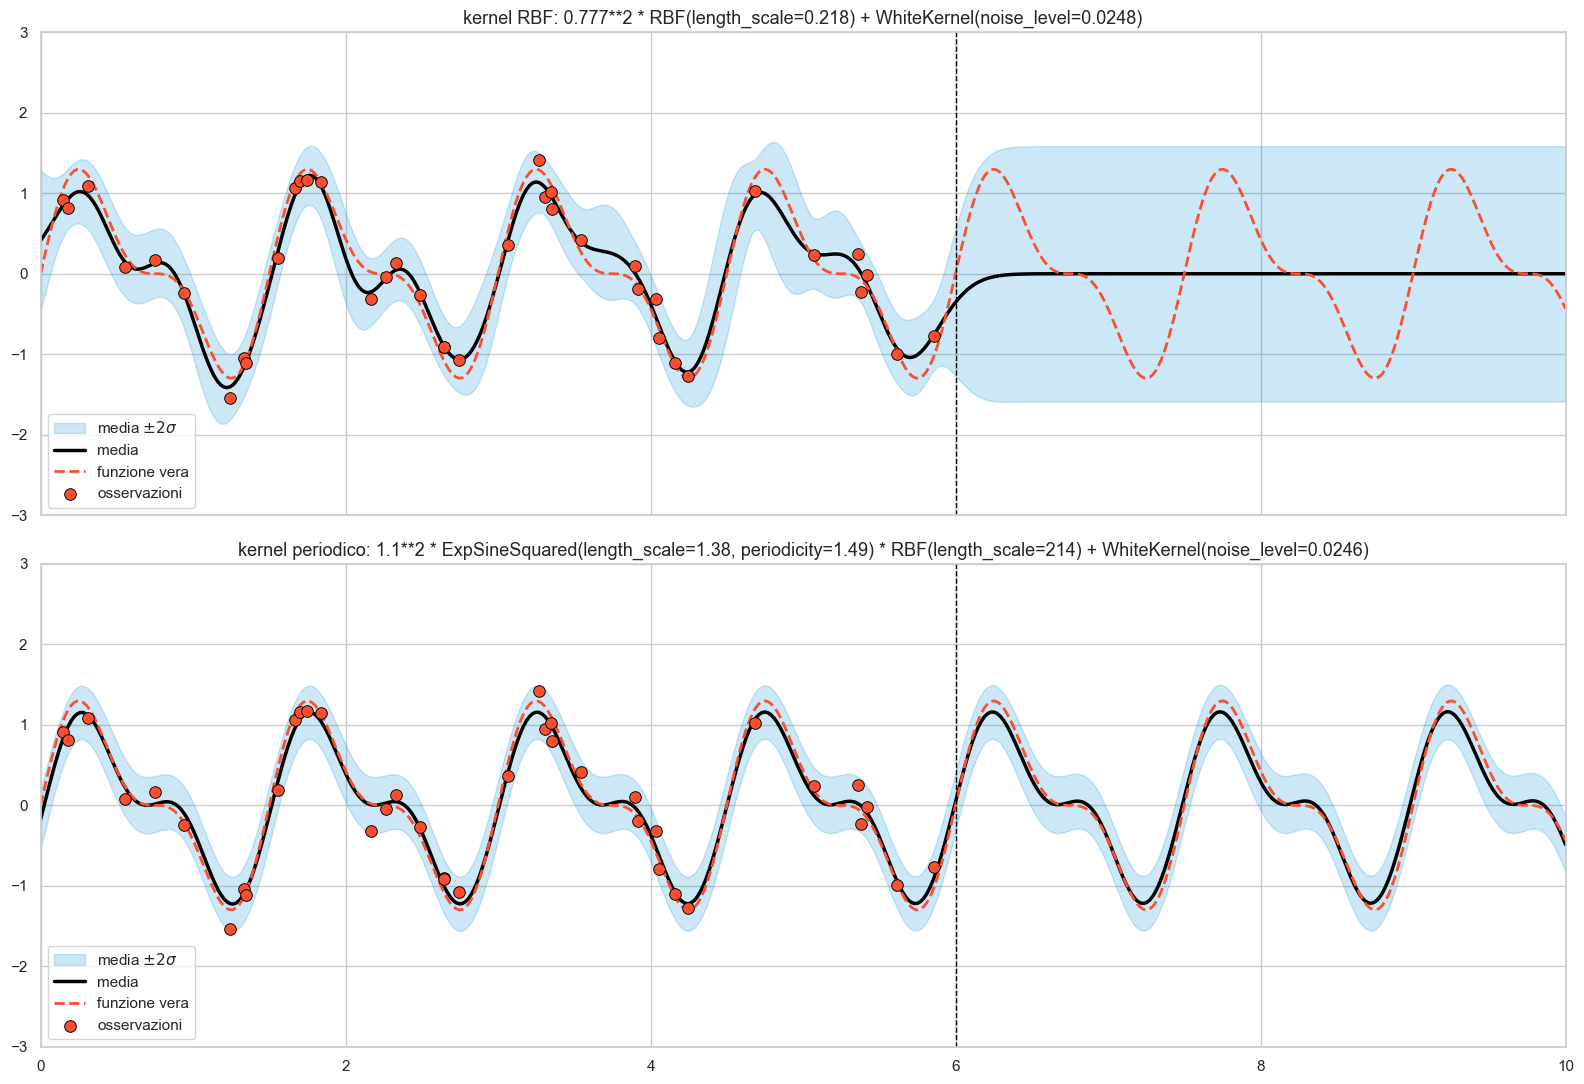

In [21]:
def f_per(x):
    return np.sin(2*np.pi*x/1.5) + 0.5*np.sin(4*np.pi*x/1.5)

rng_p = np.random.RandomState(3)
X_per = np.sort(rng_p.uniform(0, 6, 40)).reshape(-1, 1)
y_per = f_per(X_per[:, 0]) + rng_p.normal(0, 0.15, 40)
xp = np.linspace(0, 10, 500)

k_rbf = ConstantKernel(1.) * RBF(1.) + WhiteKernel(.1, (1e-5, 1.))
k_per = ConstantKernel(1.) * ExpSineSquared(length_scale=1., periodicity=1., length_scale_bounds=(1e-1, 10.), periodicity_bounds=(0.5, 3.)) * RBF(10., (1., 1e3)) + WhiteKernel(.1, (1e-5, 1.))

fig, axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True)
for ax, (name, k) in zip(axes, [('RBF', k_rbf), ('periodico', k_per)]):
    g = GaussianProcessRegressor(kernel=k, n_restarts_optimizer=10, random_state=0).fit(X_per, y_per)
    plot_gp(g, xp, 'kernel {0}: {1}'.format(name, g.kernel_), X_per, y_per, f_true=f_per, ax=ax)
    ax.axvline(6, color='black', ls='--', lw=1)
plt.tight_layout()
plt.show()

Il periodo appreso dal kernel periodico è molto vicino a quello vero ($1.5$), e la predizione oltre $x=6$ prosegue la funzione con un'incertezza simile a quella nell'intervallo dei dati: il modello è sicuro che la funzione si ripeta. La length scale dell'RBF moltiplicativo è molto grande: i dati non mostrano variazioni della forma da un periodo all'altro, e il modello appreso è di fatto strettamente periodico.

Una nota pratica: con un kernel così flessibile la verosimiglianza marginale ha molti massimi locali. Con gli intervalli di default per la length scale dell'`ExpSineSquared`, l'ottimizzatore può convergere a una soluzione degenere, con length scale minuscola e tutto il segnale attribuito al rumore, che spiega i dati in modo molto peggiore. Per questo abbiamo limitato l'intervallo di ricerca della length scale e aumentato il numero di ripartenze dell'ottimizzazione (`n_restarts_optimizer`): in generale, conviene sempre verificare che gli iperparametri appresi siano ragionevoli. L'esempio mostra il ruolo del kernel come **ipotesi a priori**: nessuna quantità di dati in $[0,6]$ permetterebbe al kernel RBF di prevedere la periodicità oltre $6$, mentre un kernel che la prevede la sfrutta pienamente. Scegliere il kernel significa decidere quali regolarità della funzione si ritengono plausibili.